In [3]:
from typing_extensions import TypedDict  , List
from langgraph.graph import StateGraph , START , END

In [5]:
class State(TypedDict):
    input_text: str
    tokens: List[str]
    char_counts: List[int]
    total_tokens: int

def tokenize_node(state: State) -> dict:
    "First node: Tokenizes input text by splitting on spaces."
    tokens = state["input_text"].split()
    return {"tokens": tokens}

def char_count_node(state: State) -> dict:
     "Parallel Node 1:Calculates character count for each token"
     counts = [len(token) for token in state["tokens"]]
     return {"char_counts": counts}

def token_count_node(state: State) -> dict:
    "Parallel Node 2: Calculates total number of tokens."
    total = len(state["tokens"])
    return {"total_tokens": total}

builder = StateGraph(State)

builder.add_node("Tokenize", tokenize_node)
builder.add_node("CharCount", char_count_node)
builder.add_node("TokenCount", token_count_node)

builder.add_edge(START, "Tokenize")

builder.add_edge("Tokenize", "CharCount")
builder.add_edge("Tokenize", "TokenCount")

builder.add_edge("CharCount", END)
builder.add_edge("TokenCount", END)

graph = builder.compile()

initial_state = {"input_text": "LangGraph makes agentic workflows parallel and simple"}
result = graph.invoke(initial_state)

print(f"Tokens: {result['tokens']}")
print(f"Character Counts per Token: {result['char_counts']}")
print(f"Total Tokens: {result['total_tokens']}")

Tokens: ['LangGraph', 'makes', 'agentic', 'workflows', 'parallel', 'and', 'simple']
Character Counts per Token: [9, 5, 7, 9, 8, 3, 6]
Total Tokens: 7


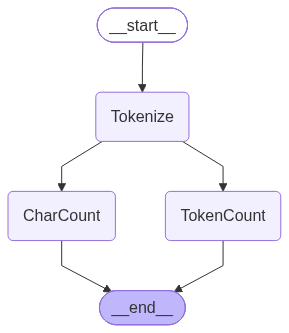

In [6]:
graph

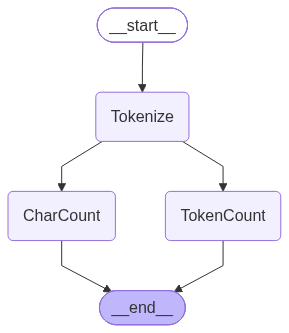

In [12]:
from IPython.display import Image , display
display(Image(graph.get_graph().draw_mermaid_png()))